# Tables and figures of the report

This notebook computes every data table and figure of the report from the files that the pipeline writes to
`results/`. It only reads JSON files, runs on a CPU in a few seconds and needs `numpy`, `pandas` and `matplotlib`.

- The outputs saved below come from our run and are the numbers printed in the report.
- After running the pipeline (`bash scripts/run.sh all`), run the notebook again to compute them from your results:
  `jupyter nbconvert --to notebook --execute --inplace paper_results.ipynb` (or `bash scripts/run.sh assets`).

Table and figure numbers follow the report. Tables 5, 6, 11 and 13 (notation, related work, datasets and
licenses, compute) do not come from these results and are not repeated here. Percentages are rounded to one decimal.

In [1]:
import gzip
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

R = Path("results")
NAME = {"sugarcrepe": "SugarCrepe", "textvqa": "TextVQA", "pope": "POPE"}
MAIN_CFG = {"sugarcrepe": "signal-first_margin_loss-strict", "textvqa": "signal-seq_min_margin_loss-strict",
            "pope": "signal-first_margin_loss-strict"}
MAIN_ALPHA = {"sugarcrepe": 0.05, "textvqa": 0.10, "pope": 0.05}
ALPHAS = (0.05, 0.10, 0.20)
GROUP_NAME = {"add_remove": "add/remove"}
C = dict(ours="#2a78d6", gpac="#eb6834", overall="#1baf7a", ref="#8a8984", ink="#0b0b0b", muted="#52514e", grid="#e4e3df")


def read(path):
    return json.loads((R / path).read_text())


T = read("F2_certify_evaluate/test_results.json")                   # SugarCrepe, TextVQA: rounds 0-4 on TEST
TP = read("P2_pope_certify_evaluate/test_results_pope.json")       # POPE
TIMING = {"sugarcrepe": read("F3_timing_test/sugarcrepe/summary.json"), "textvqa": read("F3_timing_test/textvqa/summary.json"),
          "pope": read("P3_pope_timing_test/summary.json")}        # measured latency, round-0 TEST
REDUCERS = {**read("F4_reducers_test/summary.json"),
            **{f"pope_{k}": v for k, v in read("P4_pope_reducers_test/summary.json").items()}}
S, SF, SA = (read(f"F6_rounds_extra/{f}.json") for f in ("summary", "summary_fixed", "summary_alpha"))  # 1,000 rounds
ROUNDS = json.loads(gzip.open(R / "F6_rounds_extra/rounds.json.gz").read())
LOCK = read("F0_protocol_lock/protocol_lock.json")
LOCK_POPE = read("P0_pope_protocol_lock/pope_lock.json")
pd.set_option("display.max_colwidth", None)


def pct(x, d=1):
    return "--" if x is None else f"{100 * x:.{d}f}"


def runs(ds, r):
    return TP["rounds"][r]["runs"] if ds == "pope" else T["datasets"][ds]["rounds"][r]["runs"]


def one(ds, r, config=None, rule=None, fb=None, alpha=None):
    """The one run of round r with this configuration, rule, fallback and alpha."""
    config = config or MAIN_CFG[ds]
    xs = [x for x in runs(ds, r) if x["config"] == config and (rule is None or x["rule"] == rule)
          and (fb is None or x["fallback"] == fb) and (alpha is None or x["alpha"] is None or abs(x["alpha"] - alpha) < 1e-12)]
    assert len(xs) == 1, (ds, r, config, rule, fb, alpha, len(xs))
    return xs[0]


def table(rows, columns, index=None):
    df = pd.DataFrame(rows, columns=columns)
    return df.set_index(index) if index else df.style.hide(axis="index")

## Table 1: round-0 TEST results

Save: replayed latency saving (%). Worst: highest per-type change rate on the TEST sample (%). >α: number of types
above α. Acc.: accuracy of the returned answers (%). Threshold rules use the resume fallback unless marked.

In [2]:
RULE_ROWS = [("always_cheap", "-", "Always cheap"), ("pool", None, "2×2 pooling"), ("visionzip", None, "VisionZip (640)"),
             ("group_fixed", "resume", "Per-type fixed path"), ("empirical", "resume", "Empirical threshold"),
             ("overall_ltt", "resume", "Overall LTT (CALM-style)"), ("group_crc", "resume", "Per-type CRC (expected risk)"),
             ("gpac", "resume", "G-PAC-style (each type at δ)"), ("shared_iut", "resume", "Shared threshold (IUT)"),
             ("group_ltt", "restart", "Per-type LTT (ours), restart"), ("group_ltt", "resume", "Per-type LTT, resume (ours)")]
rows = [["Always full"] + [v for ds in NAME for v in
        ("0.0", "0.0", "0", pct(one(ds, 0, rule="group_ltt", fb="resume", alpha=MAIN_ALPHA[ds])["accuracy_full"]))]]
for rule, fb, label in RULE_ROWS:
    row = [label]
    for ds in NAME:
        a = MAIN_ALPHA[ds]
        if fb is None:                                   # fixed-budget reducers
            x = REDUCERS[f"{ds}_{rule}"]
            row += [pct(x["saving"]), pct(x["groups"][x["worst"]]["rate"]),
                    str(sum(v["rate"] > a for v in x["groups"].values())), pct(x["accuracy"])]
            continue
        x = one(ds, 0, rule=rule, fb=fb, alpha=None if rule == "always_cheap" else a)
        row += [pct(x["saving"]), pct(x["worst"]), str(sum(v["rate"] is not None and v["rate"] > a for v in x["groups"].values())),
                pct(x["accuracy"])]
    rows.append(row)
cols = pd.MultiIndex.from_tuples([("", "Method")] + [(f"{NAME[ds]}, α={MAIN_ALPHA[ds]:.0%}", m) for ds in NAME
                                                      for m in ("Save", "Worst", ">α", "Acc.")])
pd.DataFrame(rows, columns=cols).set_index(("", "Method")).rename_axis("Method")

SugarCrepe, α=5%                TextVQA, α=10%  \
                                         Save Worst >α  Acc.           Save   
Method                                                                        
Always full                               0.0   0.0  0  86.9            0.0   
Always cheap                             69.3  11.0  4  86.4           57.9   
2×2 pooling                              60.9  14.8  4  81.2           50.3   
VisionZip (640)                          57.3   8.2  4  84.1           46.2   
Per-type fixed path                       0.0   0.0  0  86.9            0.0   
Empirical threshold                      63.9   6.7  2  86.7           22.3   
Overall LTT (CALM-style)                 61.9   5.7  1  86.5           19.7   
Per-type CRC (expected risk)             62.8   5.7  2  86.5           21.5   
G-PAC-style (each type at δ)             57.9   3.5  0  86.9           17.2   
Shared threshold (IUT)                   54.7   3.1  0  87.0            0.0   
Per-type LTT (ours), restart             54.2   3.5  0  87.1            9.7   
Per-type LTT, resume (ours)              56.4   3.5  0  87.1           16.4   

                                            POPE, α=5%                 
                             Worst >α  Acc.       Save Worst >α  Acc.  
Method                                                                 
Always full                    0.0  0  64.8        0.0   0.0  0  92.0  
Always cheap                  42.9  6  53.4       72.6   3.4  0  91.3  
2×2 pooling                   47.2  6  48.8       62.8   6.2  1  90.8  
VisionZip (640)               40.0  6  60.8       60.3   5.6  1  92.3  
Per-type fixed path            0.0  0  64.8        0.0   0.0  0  92.0  
Empirical threshold           28.3  3  62.4       69.6   2.8  0  91.5  
Overall LTT (CALM-style)      11.1  1  62.5       61.6   1.4  0  91.9  
Per-type CRC (expected risk)  20.8  3  62.5       68.3   2.8  0  91.5  
G-PAC-style (each type at δ)   8.7  0  63.1       64.7   2.1  0  92.0  
Shared threshold (IUT)         0.0  0  64.8       65.2   2.1  0  92.0  
Per-type LTT (ours), restart   8.3  0  63.1       61.3   2.1  0  92.0  
Per-type LTT, resume (ours)    8.7  0  63.2       63.1   2.1  0  92.0

## Figure 2: per-type change rate on round-0 TEST

95% Clopper–Pearson intervals. Hollow markers: the type always uses the full pass. Grey: always cheap.

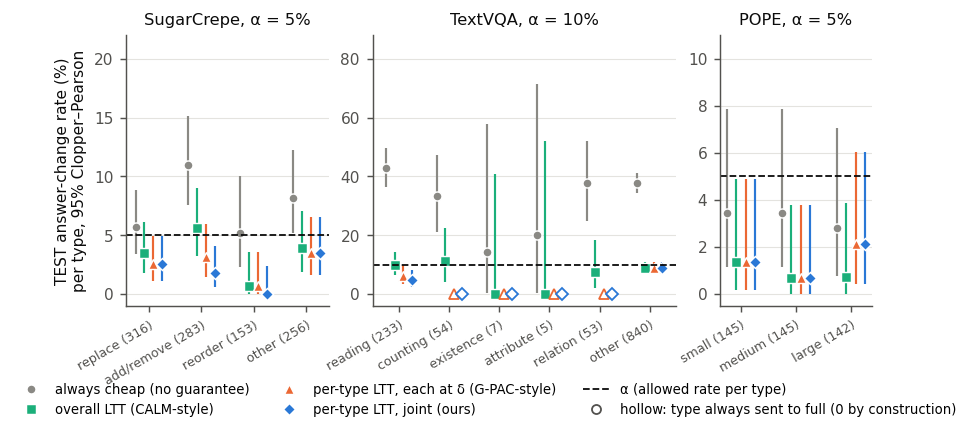

In [3]:
plt.rcParams.update({"font.size": 8.5, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": C["muted"],
                     "axes.labelcolor": C["ink"], "xtick.color": C["muted"], "ytick.color": C["muted"], "lines.linewidth": 2,
                     "figure.dpi": 130})
styles = [("always_cheap", None, C["ref"], "o", "always cheap (no guarantee)"),
          ("overall_ltt", "resume", C["overall"], "s", "overall LTT (CALM-style)"),
          ("gpac", "resume", C["gpac"], "^", "per-type LTT, each at δ (G-PAC-style)"),
          ("group_ltt", "resume", C["ours"], "D", "per-type LTT, joint (ours)")]
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.7), gridspec_kw=dict(width_ratios=[4, 6, 3]))
for ax, ds in zip(axes, NAME):
    a = MAIN_ALPHA[ds]
    ref = one(ds, 0, rule="group_ltt", fb="resume", alpha=a)["groups"]
    groups = list(ref)
    runs_ = {rule: one(ds, 0, rule=rule, fb=fb, alpha=None if rule == "always_cheap" else a) for rule, fb, *_ in styles}
    hi_all = max(100 * v["ci"][1] for rule, r in runs_.items() for v in r["groups"].values()
                 if v["rate"] is not None and (rule == "always_cheap" or v.get("threshold", 0) is not None))
    step = 5 if hi_all <= 20 else 10
    top = min(80, math.ceil(hi_all / step) * step)
    for k, (rule, fb, col, mk, lab) in enumerate(styles):
        r = runs_[rule]
        off = (k - 1.5) * 0.17
        for i, g in enumerate(groups):
            v = r["groups"][g]
            if v["rate"] is None:
                continue
            if rule != "always_cheap" and v.get("threshold", 0) is None:
                ax.plot(i + off, 0, mk, color=col, ms=5, mfc="white", mew=1, clip_on=False)
                continue
            y, lo, hi = 100 * v["rate"], 100 * v["ci"][0], 100 * v["ci"][1]
            ax.plot([i + off] * 2, [lo, min(hi, top)], color=col, lw=1.2, solid_capstyle="butt")
            if hi > top:
                ax.plot(i + off, top, "^", color=col, ms=4, clip_on=False)
                ax.annotate(f"{hi:.0f}", (i + off, top), xytext=(0, 3), textcoords="offset points", ha="center",
                            va="bottom", fontsize=6.5, color=C["muted"])
            ax.plot(i + off, y, mk, color=col, ms=5, mec="white", mew=0.8, label=lab if i == 0 else None)
    ax.axhline(100 * a, color=C["ink"], ls="--", lw=1, label="α (allowed rate per type)")
    ax.set_ylim(-top * 0.05, top * 1.1)
    ax.set_xticks(np.arange(len(groups)), [f"{GROUP_NAME.get(g, g)} ({ref[g]['n']})" for g in groups], fontsize=7,
                  rotation=30, ha="right", rotation_mode="anchor")
    ax.set_title(f"{NAME[ds]}, α = {a:.0%}", fontsize=9, color=C["ink"])
    ax.grid(axis="y", color=C["grid"], lw=0.6)
    ax.set_axisbelow(True)
axes[0].set_ylabel("TEST answer-change rate (%)\nper type, 95% Clopper–Pearson")
h, l = axes[1].get_legend_handles_labels()
h.append(plt.Line2D([], [], ls="", marker="o", color=C["muted"], mfc="white", ms=5))
l.append("hollow: type always sent to full (0 by construction)")
fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=7.3, bbox_to_anchor=(0.5, -0.24))
plt.show()

## Table 2: measured latency of our rule on round-0 TEST

Milliseconds per request (median of three runs); saving against the full pass with a 95% bootstrap interval over images.

In [4]:
rows = []
for ds, s in TIMING.items():
    for arm in ("full", "restart", "resume"):
        st = s["latency"][arm]
        saving = "--" if arm == "full" else f"{pct(s['saving'][arm])} [{pct(s['ci'][arm][0])}, {pct(s['ci'][arm][1])}]"
        rows.append([NAME[ds], arm, f"{st['mean']:.1f}", f"{st['p50']:.1f}", f"{st['p95']:.1f}", saving])
table(rows, ["Dataset", "Arm", "Mean (ms)", "p50", "p95", "Saving [95% CI]"])

Dataset,Arm,Mean (ms),p50,p95,Saving [95% CI]
SugarCrepe,full,238.7,246.7,265.6,--
SugarCrepe,restart,107.4,71.5,323.1,"55.0 [53.4, 56.5]"
SugarCrepe,resume,103.0,71.7,296.0,"56.9 [55.5, 58.2]"
TextVQA,full,327.6,309.4,441.8,--
TextVQA,restart,295.6,272.6,599.8,"9.8 [7.2, 12.4]"
TextVQA,resume,272.9,274.5,537.2,"16.7 [14.4, 19.0]"
POPE,full,435.8,447.9,484.8,--
POPE,restart,169.8,120.2,576.7,"61.0 [59.5, 62.5]"
POPE,resume,161.2,120.5,499.6,"63.0 [61.7, 64.3]"


## Table 3: 1,000 CAL/TEST rounds at each dataset's α

Resume fallback. Save: mean ± s.d. (%). >α: share of rounds (%) in which some type's held-out rate exceeds α.
†No calibration, so rounds differ only in the TEST split; Save is the round-0 value.

In [5]:
REDRAW_RULES = [("group_ltt", "Ours (all types at once)"), ("gpac", "G-PAC-style (each type alone)"),
                ("shared_iut", "Shared threshold (IUT)"), ("overall_ltt", "Overall LTT (CALM-style)"),
                ("group_crc", "Per-type CRC (expected risk)"), ("empirical", "Empirical threshold")]
FIXED_RULES = [("always_cheap", "Always cheap†"), ("visionzip", "VisionZip (640)†")]
f1 = lambda v: f"{v:.1f}"
share = lambda x, k: f"{100 * x[k] / x['rounds']:.1f}"
rows = []
for rule, label in REDRAW_RULES:
    rows.append([label] + [v for ds in NAME for v in
                 (f"{f1(S[ds][rule]['saving_mean'])} ± {f1(S[ds][rule]['saving_sd'])}", share(S[ds][rule], "exceed_heldout"))])
for rule, label in FIXED_RULES:
    rows.append([label] + [v for ds in NAME for v in (f1(SF[ds][rule]["saving_round0"]), share(SF[ds][rule], "exceed_heldout"))])
cols = pd.MultiIndex.from_tuples([("", "Method")] + [(f"{NAME[ds]}, α={MAIN_ALPHA[ds]:.0%}", m) for ds in NAME for m in ("Save", ">α")])
pd.DataFrame(rows, columns=cols).set_index(("", "Method")).rename_axis("Method")

SugarCrepe, α=5%        TextVQA, α=10%         \
                                          Save     >α           Save     >α   
Method                                                                        
Ours (all types at once)            56.3 ± 2.0    7.0     14.6 ± 1.9    5.1   
G-PAC-style (each type alone)       59.3 ± 1.7   23.6     16.4 ± 1.8   22.0   
Shared threshold (IUT)              55.3 ± 2.9    2.1      1.0 ± 3.0    6.8   
Overall LTT (CALM-style)            61.2 ± 2.1   22.4     18.2 ± 1.9   74.8   
Per-type CRC (expected risk)        63.2 ± 1.6   75.3     19.4 ± 1.8   88.6   
Empirical threshold                 64.2 ± 1.1   83.9     20.5 ± 1.8   97.0   
Always cheap†                             69.3  100.0           57.9  100.0   
VisionZip (640)†                          57.3  100.0           46.2  100.0   

                               POPE, α=5%        
                                     Save    >α  
Method                                           
Ours (all types at once)       60.0 ± 8.4   2.4  
G-PAC-style (each type alone)  65.8 ± 4.5   6.9  
Shared threshold (IUT)         62.6 ± 5.9   0.2  
Overall LTT (CALM-style)       66.2 ± 4.6   9.3  
Per-type CRC (expected risk)   70.7 ± 1.5  32.6  
Empirical threshold            71.2 ± 0.9  30.8  
Always cheap†                        72.6  74.6  
VisionZip (640)†                     60.3   5.6

## Table 4: ablations on round-0 TEST at the main α

Restart fallback unless marked. The accuracy-drop rows need correctness labels; their Worst counts drops in accuracy.

In [6]:
rows = []
for ds in NAME:
    a, main = MAIN_ALPHA[ds], MAIN_CFG[ds]
    items = [("fallback", "restart", one(ds, 0, config=main, rule="group_ltt", fb="restart", alpha=a)),
             ("fallback", "resume (main)", one(ds, 0, config=main, rule="group_ltt", fb="resume", alpha=a))]
    if ds == "textvqa":
        items.append(("signal", "first-token margin",
                      one(ds, 0, config="signal-first_margin_loss-strict", rule="group_ltt", fb="restart", alpha=a)))
    sig = "seq_min_margin" if ds == "textvqa" else "first_margin"
    items.append(("loss", "accuracy drop (labels)", one(ds, 0, config=f"signal-{sig}_loss-acc_drop", rule="group_ltt", fb="restart", alpha=a)))
    rows += [[NAME[ds], ab, setting, pct(x["saving"]), pct(x["worst"]), pct(x["accuracy"])] for ab, setting, x in items]
    if ds == "pope":
        cell = f"answer margin (main) {TP['auroc_round0']['first_margin']:.3f}"
    else:
        au = {k: v for k, v in T["datasets"][ds]["auroc"].items() if k not in ("n", "changed_rate")}
        ms = "seq_min_margin" if ds == "textvqa" else "first_margin"
        best = max(au, key=au.get)
        label = "answer margin" if ds == "sugarcrepe" else ms.replace("_", " ")
        cell = f"{label} (main) {au[ms]:.3f}" + (f"; first-token margin {au['first_margin']:.3f}" if ds == "textvqa" else "") \
            + ("" if best == ms else f"; best {best.replace('_', ' ')} {au[best]:.3f}")
    rows.append([NAME[ds], "AUROC", cell, "", "", ""])
table(rows, ["Dataset", "Ablation", "Setting", "Save", "Worst", "Acc."])

Dataset,Ablation,Setting,Save,Worst,Acc.
SugarCrepe,fallback,restart,54.2,3.5,87.1
SugarCrepe,fallback,resume (main),56.4,3.5,87.1
SugarCrepe,loss,accuracy drop (labels),63.2,4.3,86.6
SugarCrepe,AUROC,answer margin (main) 0.906,,,
TextVQA,fallback,restart,9.7,8.3,63.1
TextVQA,fallback,resume (main),16.4,8.7,63.2
TextVQA,signal,first-token margin,1.2,6.9,62.6
TextVQA,loss,accuracy drop (labels),19.2,6.3,61.8
TextVQA,AUROC,seq min margin (main) 0.844; first-token margin 0.714; best seq mean logp 0.850,,,
POPE,fallback,restart,61.3,2.1,92.0


## Table 7: our rule on round-0 TEST, per type

Certified threshold (*full*: none, the type uses the full pass), changes k/n on the TEST sample and 95% Clopper–Pearson
intervals. Thresholds are on the scale of each dataset's confidence.

In [7]:
rows = []
for ds in NAME:
    x = one(ds, 0, rule="group_ltt", fb="resume", alpha=MAIN_ALPHA[ds])
    for g, v in x["groups"].items():
        th = "full" if v["threshold"] is None else np.format_float_positional(v["threshold"], precision=3, unique=False, fractional=False)
        ci = "--" if v["rate"] is None else f"[{pct(v['ci'][0])}, {pct(v['ci'][1])}]"
        rows.append([NAME[ds], GROUP_NAME.get(g, g), th, f"{v['k']}/{v['n']}", pct(v["rate"]), ci])
table(rows, ["Dataset", "Type", "Threshold", "k/n", "Rate (%)", "95% CI (%)"])

Dataset,Type,Threshold,k/n,Rate (%),95% CI (%)
SugarCrepe,replace,0.625,8/316,2.5,"[1.1, 4.9]"
SugarCrepe,add/remove,0.922,5/283,1.8,"[0.6, 4.1]"
SugarCrepe,reorder,0.997,0/153,0.0,"[0.0, 2.4]"
SugarCrepe,other,0.562,9/256,3.5,"[1.6, 6.6]"
TextVQA,reading,0.374,11/233,4.7,"[2.4, 8.3]"
TextVQA,counting,full,0/54,0.0,"[0.0, 6.6]"
TextVQA,existence,full,0/7,0.0,"[0.0, 41.0]"
TextVQA,attribute,full,0/5,0.0,"[0.0, 52.2]"
TextVQA,relation,full,0/53,0.0,"[0.0, 6.7]"
TextVQA,other,0.217,73/840,8.7,"[6.9, 10.8]"


## Table 8: all 1,000 rounds at three values of α

Saving and worst-type rate on the TEST sample (mean ± s.d., %) and >α, the share of rounds (%) in which some type's
held-out rate exceeds α.

In [8]:
names = {"group_ltt": "Ours", "gpac": "G-PAC-style", "shared_iut": "Shared (IUT)", "overall_ltt": "Overall LTT"}
rows = []
for a in ALPHAS:
    for rule, fb in (("group_ltt", "resume"), ("group_ltt", "restart"), ("gpac", "resume"), ("shared_iut", "resume"),
                     ("overall_ltt", "resume")):
        row = [f"{a:.0%}", f"{names[rule]}, {fb}"]
        for ds in NAME:
            x = SA[ds][f"{a:g}"][f"{rule}|{fb}"]
            row += [f"{x['saving_mean']:.1f} ± {x['saving_sd']:.1f}", f"{x['worst_mean']:.1f} ± {x['worst_sd']:.1f}",
                    f"{100 * x['exceed_heldout'] / x['rounds']:.1f}"]
        rows.append(row)
cols = pd.MultiIndex.from_tuples([("", "α"), ("", "Method")] + [(NAME[ds], m) for ds in NAME for m in ("Save", "Worst", ">α")])
pd.DataFrame(rows, columns=cols).set_index([("", "α"), ("", "Method")]).rename_axis(["α", "Method"])

SugarCrepe                       TextVQA  \
                                Save       Worst    >α        Save   
α   Method                                                           
5%  Ours, resume          56.3 ± 2.0   3.5 ± 1.1   7.0   4.5 ± 1.6   
    Ours, restart         54.6 ± 2.3   3.4 ± 1.1   7.6  -3.4 ± 2.5   
    G-PAC-style, resume   59.3 ± 1.7   4.2 ± 1.3  23.6   5.3 ± 1.9   
    Shared (IUT), resume  55.3 ± 2.9   2.8 ± 1.0   2.1   2.9 ± 2.5   
    Overall LTT, resume   61.2 ± 2.1   4.5 ± 1.3  22.4   6.1 ± 1.9   
10% Ours, resume          66.0 ± 1.0   7.1 ± 1.7   1.8  14.6 ± 1.9   
    Ours, restart         65.5 ± 1.2   7.1 ± 1.7   1.7   8.0 ± 2.3   
    G-PAC-style, resume   67.2 ± 1.0   8.1 ± 1.6   7.3  16.4 ± 1.8   
    Shared (IUT), resume  64.3 ± 1.9   6.3 ± 1.7   1.8   1.0 ± 3.0   
    Overall LTT, resume   68.6 ± 1.7   9.3 ± 1.9  37.7  18.2 ± 1.9   
20% Ours, resume          69.5 ± 0.2  10.0 ± 1.4   0.0  28.3 ± 2.2   
    Ours, restart         69.5 ± 0.2  10.0 ± 1.4   0.0  23.6 ± 2.5   
    G-PAC-style, resume   69.5 ± 0.2  10.0 ± 1.4   0.0  30.1 ± 1.7   
    Shared (IUT), resume  69.5 ± 0.2  10.0 ± 1.4   0.0  16.3 ± 5.2   
    Overall LTT, resume   69.5 ± 0.2  10.0 ± 1.4   0.0  32.4 ± 1.6   

                                                  POPE                  
                               Worst    >α        Save      Worst   >α  
α   Method                                                              
5%  Ours, resume           3.2 ± 1.0   6.4  60.0 ± 8.4  2.8 ± 1.4  2.4  
    Ours, restart          3.3 ± 1.1   3.2  58.6 ± 8.3  2.8 ± 1.4  2.4  
    G-PAC-style, resume    3.7 ± 1.8  13.9  65.8 ± 4.5  3.5 ± 1.5  6.9  
    Shared (IUT), resume   2.0 ± 1.7   0.9  62.6 ± 5.9  2.2 ± 1.2  0.2  
    Overall LTT, resume    8.6 ± 3.2  85.0  66.2 ± 4.6  3.0 ± 1.6  9.3  
10% Ours, resume           7.8 ± 1.8   5.1  71.7 ± 1.2  5.3 ± 1.6  0.0  
    Ours, restart          7.8 ± 1.8   5.5  71.5 ± 1.4  5.3 ± 1.6  0.0  
    G-PAC-style, resume    9.3 ± 2.7  22.0  72.4 ± 0.8  5.6 ± 1.6  0.0  
    Shared (IUT), resume   1.2 ± 3.6   6.8  71.6 ± 1.9  5.2 ± 1.9  0.0  
    Overall LTT, resume   12.6 ± 3.3  74.8  72.4 ± 1.3  5.6 ± 1.7  0.0  
20% Ours, resume          17.3 ± 2.9   7.9  72.9 ± 0.2  5.9 ± 1.5  0.0  
    Ours, restart         17.3 ± 2.8   8.0  72.9 ± 0.2  5.9 ± 1.5  0.0  
    G-PAC-style, resume   19.5 ± 5.2  19.4  72.9 ± 0.2  5.9 ± 1.5  0.0  
    Shared (IUT), resume  11.6 ± 5.7   7.0  72.9 ± 0.2  5.9 ± 1.5  0.0  
    Overall LTT, resume   21.6 ± 3.6  56.5  72.9 ± 0.2  5.9 ± 1.5  0.0

## Table 9: all counts of the 1,000 rounds at each dataset's α

Resume fallback. Saving and worst-type rate on the TEST sample (mean ± s.d., %) and the share of rounds (%) with a type
above α on the TEST sample, on all TEST questions (held-out) and on all CAL and TEST images (pool).
†No calibration; Save is the round-0 value.

In [9]:
rows = []
for ds in NAME:
    for rule, label in REDRAW_RULES:
        x = S[ds][rule]
        rows.append([NAME[ds], label, f"{f1(x['saving_mean'])} ± {f1(x['saving_sd'])}", f"{f1(x['worst_mean'])} ± {f1(x['worst_sd'])}",
                     share(x, "exceed_test"), share(x, "exceed_heldout"), share(x, "exceed_pool")])
    for rule, label in FIXED_RULES:
        x = SF[ds][rule]
        rows.append([NAME[ds], label, f1(x["saving_round0"]), f"{f1(x['worst_mean'])} ± {f1(x['worst_sd'])}",
                     share(x, "exceed_test"), share(x, "exceed_heldout"), share(x, "exceed_pool")])
table(rows, ["Dataset", "Method", "Save", "Worst", ">α, TEST sample", ">α, held-out", ">α, pool"])

Dataset,Method,Save,Worst,">α, TEST sample",">α, held-out",">α, pool"
SugarCrepe,Ours (all types at once),56.3 ± 2.0,3.5 ± 1.1,8.9,7.0,0.0
SugarCrepe,G-PAC-style (each type alone),59.3 ± 1.7,4.2 ± 1.3,23.0,23.6,0.2
SugarCrepe,Shared threshold (IUT),55.3 ± 2.9,2.8 ± 1.0,2.7,2.1,0.0
SugarCrepe,Overall LTT (CALM-style),61.2 ± 2.1,4.5 ± 1.3,29.7,22.4,8.0
SugarCrepe,Per-type CRC (expected risk),63.2 ± 1.6,5.9 ± 1.5,74.6,75.3,8.8
SugarCrepe,Empirical threshold,64.2 ± 1.1,6.1 ± 1.4,82.1,83.9,11.7
SugarCrepe,Always cheap†,69.3,10.0 ± 1.4,100.0,100.0,100.0
SugarCrepe,VisionZip (640)†,57.3,9.9 ± 1.2,100.0,100.0,100.0
TextVQA,Ours (all types at once),14.6 ± 1.9,7.8 ± 1.8,7.1,5.1,0.6
TextVQA,G-PAC-style (each type alone),16.4 ± 1.8,9.3 ± 2.7,23.8,22.0,6.2


## Table 10: further numbers quoted in the text

At each dataset's main α. Extra time of a fallback: mean over the requests that fall back, compared with the full pass
alone. The last three rows use the held-out rate over the 1,000 rounds.

In [10]:
rows = {k: [] for k in ("ri", "cov", "save", "fb", "extra", "gain", "mem", "cov_r", "ov", "gp")}
for ds in NAME:
    a = MAIN_ALPHA[ds]
    x, s = one(ds, 0, rule="group_ltt", fb="resume", alpha=a), TIMING[ds]
    rows["ri"].append(f"{pct(x['overall_RI']['rate'])} ({x['overall_RI']['k']}/{x['overall_RI']['n']})")
    rows["cov"].append(pct(x["coverage"]))
    rows["save"].append(f"{pct(x['saving'])} [{pct(x['saving_ci'][0])}, {pct(x['saving_ci'][1])}]")
    rows["fb"].append(pct(s["actions"]["resume"]["fallback"] / s["n"]))
    rows["extra"].append(f"{s['fallback_extra']['restart']['mean']:.0f} / {s['fallback_extra']['resume']['mean']:.0f}")
    gain, ci = s["saving"]["resume"] - s["saving"]["restart"], s["ci"]["resume_minus_restart"]
    rows["gain"].append(f"{pct(gain)} [{pct(ci[0])}, {pct(ci[1])}]")
    rows["mem"].append(f"{s['peak_mib']['full'] / 1024:.1f} / {s['peak_mib']['resume'] / 1024:.1f}")
    rs = ROUNDS[ds]["rounds"]
    key = lambda rule: f"{a:g}|{rule}|resume"
    rows["cov_r"].append(pct(np.mean([r[key("group_ltt")]["coverage"] for r in rs])))
    for name, rule in (("ov", "overall_ltt"), ("gp", "gpac")):
        types = list(rs[0][key(rule)]["heldout"])
        shares = {t: np.mean([(r[key(rule)]["heldout"].get(t) or 0) > a + 1e-12 for r in rs]) for t in types}
        t = max(shares, key=shares.get)
        rows[name].append(f"{pct(shares[t])} ({GROUP_NAME.get(t, t)})")
labels = {"ri": "Per-image change rate R_I (%, k/n)", "cov": "Coverage: requests in certified types (%)",
          "save": "Replayed saving [95% CI] (%)", "fb": "Requests that fall back, measured (%)",
          "extra": "Extra time of a fallback over the full pass, restart / resume (ms)",
          "gain": "Measured saving, resume minus restart [95% CI] (points)",
          "mem": "Peak GPU memory, full pass / resume policy (GiB)", "cov_r": "Coverage, mean over the 1,000 rounds (%)",
          "ov": "Overall LTT: most frequent type above α (% of rounds)",
          "gp": "G-PAC-style: most frequent type above α (% of rounds)"}
pd.DataFrame([[labels[k]] + v for k, v in rows.items()], columns=["Quantity"] + [NAME[ds] for ds in NAME]).set_index("Quantity")

,SugarCrepe,TextVQA,POPE
Quantity,,,
"Per-image change rate R_I (%, k/n)",2.0 (9/455),6.9 (68/987),0.0 (0/145)
Coverage: requests in certified types (%),100.0,92.4,100.0
Replayed saving [95% CI] (%),"56.4 [55.0, 57.7]","16.4 [14.2, 18.6]","63.1 [61.8, 64.4]"
"Requests that fall back, measured (%)",15.0,42.6,11.3
"Extra time of a fallback over the full pass, restart / resume (ms)",71 / 40,144 / 92,127 / 48
"Measured saving, resume minus restart [95% CI] (points)","1.9 [1.6, 2.1]","6.9 [6.4, 7.5]","2.0 [1.7, 2.3]"
"Peak GPU memory, full pass / resume policy (GiB)",13.5 / 14.9,14.9 / 14.9,13.5 / 14.9
"Coverage, mean over the 1,000 rounds (%)",100.0,92.9,95.1
Overall LTT: most frequent type above α (% of rounds),21.9 (add/remove),62.1 (counting),8.9 (small)


## Table 12: round-0 CAL and TEST counts per type and the outcome of our rule

Resume fallback, main α. A type is eligible when its CAL count reaches the minimum for its level; an eligible type gets
a threshold if at least its strictest candidate passes the test.

In [11]:
CERTS = {"sugarcrepe": read("F2_certify_evaluate/certificates.json")["datasets"]["sugarcrepe"][0],
         "textvqa": read("F2_certify_evaluate/certificates.json")["datasets"]["textvqa"][0],
         "pope": read("P2_pope_certify_evaluate/certificates_pope.json")["rounds"][0]}
rows = []
for ds in NAME:
    a = MAIN_ALPHA[ds]
    lock = LOCK_POPE["rounds"][0] if ds == "pope" else LOCK["datasets"][ds]["rounds"][0]
    el = lock["eligibility"][f"{a:g}"]
    x = one(ds, 0, rule="group_ltt", fb="resume", alpha=a)
    cert = next(c for c in CERTS[ds]["runs"] if c["rule"] == "group_ltt" and c["fallback"] == "resume"
                and c["config"] == MAIN_CFG[ds] and abs(c["alpha"] - a) < 1e-12)
    for g, v in x["groups"].items():
        first = (cert.get("trace") or {}).get(g) or [{}]
        losses = first[0].get("tests", [[None, None]])[0][1]     # [n, losses, p] at the strictest candidate
        outcome = ("certified" if v["threshold"] is not None else
                   f"eligible, first candidate fails ({losses} losses)" if g in el["eligible"] else "ineligible")
        rows.append([NAME[ds], GROUP_NAME.get(g, g), el["n_cal"][g], v["n"], outcome])
table(rows, ["Dataset", "Type", "CAL n", "TEST n", "Outcome"])

Dataset,Type,CAL n,TEST n,Outcome
SugarCrepe,replace,317,316,certified
SugarCrepe,add/remove,282,283,certified
SugarCrepe,reorder,154,153,certified
SugarCrepe,other,264,256,certified
TextVQA,reading,241,233,certified
TextVQA,counting,43,54,"eligible, first candidate fails (3 losses)"
TextVQA,existence,12,7,ineligible
TextVQA,attribute,13,5,ineligible
TextVQA,relation,37,53,ineligible
TextVQA,other,792,840,certified


## Table 14: POPE, round-0 TEST, by setting

Full pass, cheap pass and our policy (α = 5%). Recall and precision are for the answer *yes*; Yes-ratio is the share
of *yes* answers given; n: questions.

In [12]:
st = one("pope", 0, rule="group_ltt", fb="resume", alpha=MAIN_ALPHA["pope"])["settings"]
rows = []
for s in ("random", "popular", "adversarial"):
    for k, label in (("full", "full pass"), ("cheap", "cheap pass"), ("certified", "ours")):
        v = st[s][k]
        rows.append([s, label, pct(v["accuracy"]), pct(v["recall"]), pct(v["precision"]), pct(v["f1"]), pct(v["yes_ratio"]), v["n"]])
table(rows, ["Setting", "Answers", "Accuracy", "Recall", "Precision", "F1", "Yes-ratio", "n"])

Setting,Answers,Accuracy,Recall,Precision,F1,Yes-ratio,n
random,full pass,89.1,79.5,98.3,87.9,40.5,870
random,cheap pass,86.7,73.8,99.4,84.7,37.1,870
random,ours,88.0,77.2,98.5,86.6,39.2,870
popular,full pass,88.4,79.5,96.6,87.3,41.1,870
popular,cheap pass,86.1,73.8,97.9,84.1,37.7,870
popular,ours,87.7,77.2,97.7,86.3,39.5,870
adversarial,full pass,87.0,79.5,93.5,86.0,42.5,870
adversarial,cheap pass,85.4,73.8,96.1,83.5,38.4,870
adversarial,ours,86.8,77.2,95.5,85.4,40.5,870


## Figure 3: replayed saving against α

Mean over the 1,000 rounds; band: 10th to 90th percentile. Dashed: always cheap (mean over the rounds).

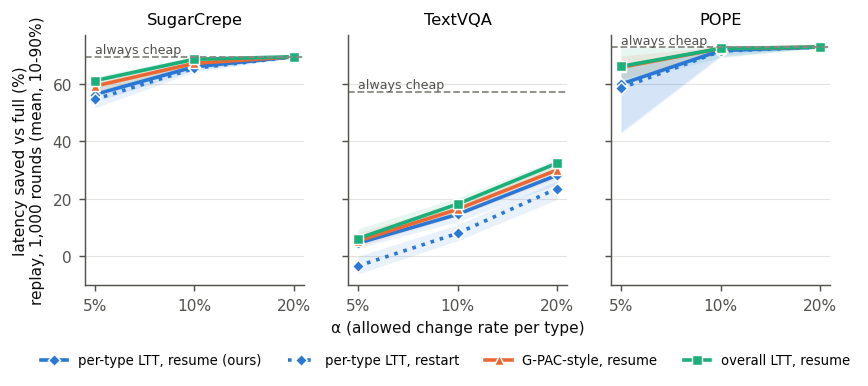

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.5), sharey=True)
lines = [("group_ltt", "resume", C["ours"], "D", "-", "per-type LTT, resume (ours)"),
         ("group_ltt", "restart", C["ours"], "D", ":", "per-type LTT, restart"),
         ("gpac", "resume", C["gpac"], "^", "-", "G-PAC-style, resume"),
         ("overall_ltt", "resume", C["overall"], "s", "-", "overall LTT, resume")]
for ax, ds in zip(axes, NAME):
    for rule, fb, col, mk, ls, lab in lines:
        xs = [SA[ds][f"{a:g}"][f"{rule}|{fb}"] for a in ALPHAS]
        ax.fill_between(range(3), [x["saving_p10"] for x in xs], [x["saving_p90"] for x in xs], color=col, alpha=0.10, lw=0)
        ax.plot(range(3), [x["saving_mean"] for x in xs], ls=ls, marker=mk, color=col, ms=5, mec="white", mew=0.8, label=lab)
    ch = SA[ds]["always_cheap_saving"]
    ax.axhline(ch, color=C["ref"], lw=1, ls="--")
    ax.text(0, ch, "always cheap", va="bottom", fontsize=7, color=C["muted"])
    ax.set_xticks(range(3), [f"{a:.0%}" for a in ALPHAS])
    if ds == "textvqa":
        ax.set_xlabel("α (allowed change rate per type)")
    ax.set_title(NAME[ds], fontsize=9)
    ax.grid(axis="y", color=C["grid"], lw=0.6)
    ax.set_axisbelow(True)
axes[0].set_ylabel("latency saved vs full (%)\nreplay, 1,000 rounds (mean, 10-90%)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, fontsize=7.3, bbox_to_anchor=(0.5, -0.18))
plt.show()

## Figure 4: measured latency per request on round-0 TEST

Accepted cheap answers are the fast part of each policy curve; fallbacks form the tail.

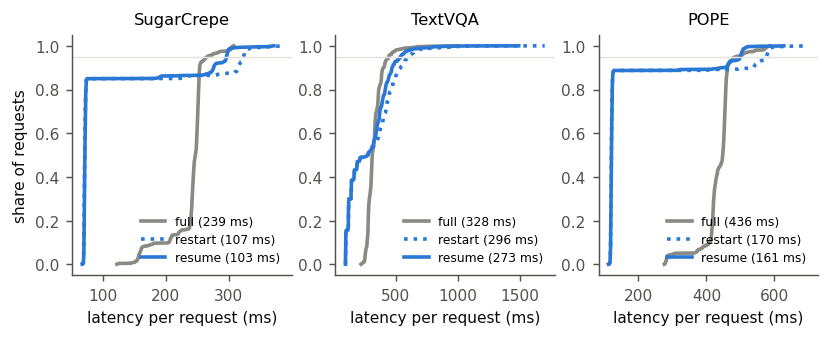

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.4))
for ax, ds in zip(axes, NAME):
    path = R / ("P3_pope_timing_test" if ds == "pope" else f"F3_timing_test/{ds}") / "traces.jsonl"
    rows = [json.loads(line) for line in open(path)]
    for arm, col, ls in (("full", C["ref"], "-"), ("restart", C["ours"], ":"), ("resume", C["ours"], "-")):
        v = np.sort([r[f"ms_{arm}"] for r in rows])
        ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=col, ls=ls, label=f"{arm} ({v.mean():.0f} ms)")
    ax.axhline(0.95, color=C["grid"], lw=0.8)
    ax.set_xlabel("latency per request (ms)")
    ax.set_title(NAME[ds], fontsize=9)
    ax.legend(frameon=False, fontsize=6.8, loc="lower right")
axes[0].set_ylabel("share of requests")
plt.show()